### Phase 3 (Data Preparation)

In [1]:
import os
from dotenv import load_dotenv
from pathlib import Path
import duckdb
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
#from sklearn.model_selection import GroupKFold
from sklearn.model_selection import train_test_split
import numpy as np
import requests

### Ladataan projektin juuren .env-tiedosto

Projektin juuressa sijaitseva `.env`-tiedosto sisältää käyttäjäkohtaiset asetukset,
joita ei jaeta Gitissä — kuten `DATA_PATH`, joka osoittaa paikalliseen data-kansioon.
Näin koodiin ei tarvitse kovakoodata tiedostopolkuja ja jokainen kehittäjä voi käyttää
omaa sijaintiaan.

In [2]:
load_dotenv()

# Luetaan datakansion polku .env-tiedostosta
DATA_PATH = Path(os.getenv("DATA_PATH"))

### Ladataan ja esikäsitellään data – tallennetaan välivaiheen parquet

Tämä skripti muuntaa raakamuotoisen CSV-tiedoston (10GB) parquet-muotoon.
Parquet on sarakeperusteinen tiedostoformaatti joka:
  - Pakkaa datan pienemmäksi (10GB → ~3GB)
  - Mahdollistaa yksittäisten sarakkeiden lataamisen ilman koko tiedoston lukemista
  - On huomattavasti nopeampi ladata kuin CSV
  
DuckDB hoitaa muunnoksen suoraan levyltä ilman että koko CSV ladataan muistiin, mikä mahdollistaa 10GB tiedoston käsittelyn myös pienellä RAM-määrällä.


In [3]:
# =============================================================================
# ESIKÄSITELTY VÄLITALLENNE: PARQUET
# =============================================================================
# Tarkistetaan onko esikäsitelty parquet jo olemassa.
# Jos on → ladataan suoraan, ohitetaan koko esikäsittely.
# Jos ei → luodaan ensin parquet CSV:stä, ajetaan esikäsittely ja tallennetaan.
# =============================================================================

raw_path     = DATA_PATH / "used_cars_data.parquet"
cleaned_path = DATA_PATH / "used_cars_data_cleaned.parquet"

# Luodaan raakadata-parquet CSV:stä jos sitä ei ole
if not raw_path.exists():
    print("Luodaan parquet CSV:stä...")
    duckdb.execute(f"""
        COPY (
            SELECT * FROM read_csv_auto('{str(DATA_PATH / "used_cars_data.csv")}',
                types={{'dealer_zip': 'VARCHAR'}}
            )
            LIMIT 10000
        ) TO '{str(raw_path)}'
        (FORMAT PARQUET)
    """)
    print(f"Valmis! Tallennettu: {raw_path}")

# Ladataan esikäsitelty data jos olemassa, muuten ajetaan esikäsittely
if cleaned_path.exists():
    df = pl.read_parquet(cleaned_path)
    print(f"Ladattu välivaiheen tiedosto: {df.shape[0]:,} riviä, {df.shape[1]} saraketta")
else:
    df = pl.scan_parquet(raw_path)

    # Tarkistus raakadatalle
    # df.describe()

    df_lazy = (
        df
        .select([
            "body_type", "daysonmarket", "engine_displacement", "engine_type",
            "mileage", "fuel_type", "horsepower", "latitude", "longitude",
            "major_options", "make_name", "model_name", "price",
            "transmission_display", "wheel_system", "year", "listed_date", "length"
        ])
        .filter(pl.col("price").is_between(1000, 150000))
        .filter((pl.col("mileage") < 500000) | pl.col("mileage").is_null())
        .filter(pl.col("year").is_between(1990, 2023))
        .filter(pl.col("latitude").is_not_null()) # Geo-featuret vaativat koordinaatit
        .filter(pl.col("longitude").is_not_null())
        .unique() # Poistetaan duplikaatit
    )
    df = df_lazy.collect()
    df.write_parquet(cleaned_path)
    
    print(f"Tallennettu: {df.shape[0]:,} riviä, {df.shape[1]} saraketta")

Ladattu välivaiheen tiedosto: 9,646 riviä, 18 saraketta


### Puuttuvien arvojen Heatmap ennen käsittelyä

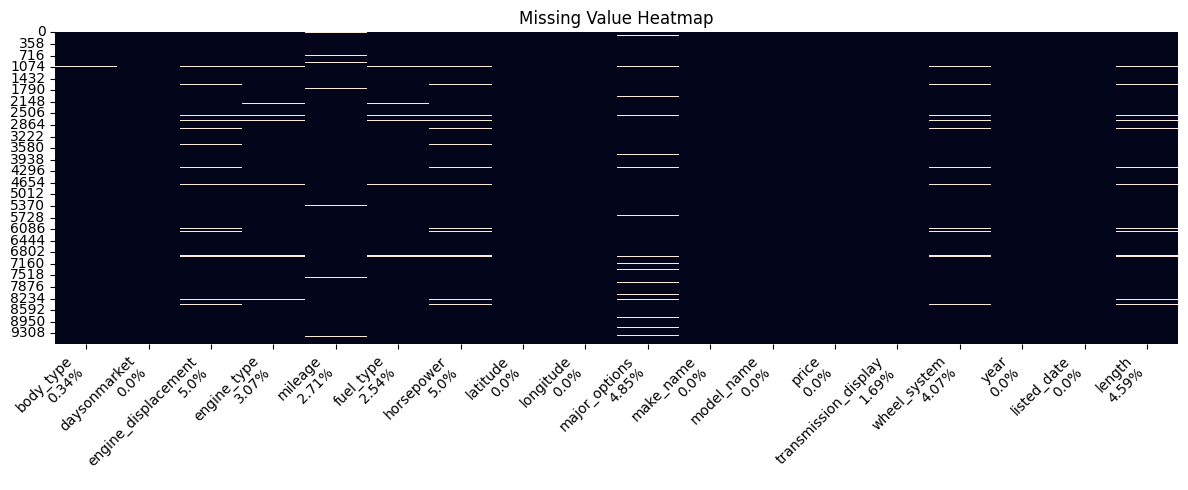

In [4]:
# --- Muutetaan Polars → Pandas vain heatmapin ajaksi ---
pdf = df.to_pandas()

missing_pct = (pdf.isnull().mean() * 100).round(2)

plt.figure(figsize=(12,5))
ax = sns.heatmap(pdf.isnull(), cbar=False)

# lisää prosentit x‑akselin labeleihin
new_labels = [
    f"{col}\n{missing_pct[col]}%" for col in pdf.columns
]

ax.set_xticklabels(new_labels, rotation=45, ha="right")
plt.title("Missing Value Heatmap")
plt.tight_layout()
plt.show()

# --- Palautetaan Pandas → Polars ---
df = pl.from_pandas(pdf)

### Puuttuvien arvojen imputointi

| # | Sarake | Menetelmä |
|---|--------|-----------|
| 1 | Horsepower | Mediaani merkin + mallin mukaan |
| 2 | Mileage | Mediaani vuosimallin mukaan |
| 3 | Fuel Type | Yleisin arvo: make+model+year → make+model → make |
| 4 | Body Type | Yleisin arvo: make+model → make |
| 5 | Engine Type | Yleisin arvo: make+model → make |
| 6 | Transmission | Yleisin arvo: make+model → make |
| 7 | Wheel System | Yleisin arvo: make+model → make |
| 8 | Engine Displacement | Mediaani merkin + mallin mukaan. Poikkeus: Fuel Type 'Electric' → 0 |
| 9 | Length | YMediaani make+model → make → body_type + length_missing‑flag |
| 10 | Major Options | Täytetään tyhjällä listalla `[]` |

In [5]:
# Muutetaan sarakkeet varmasti oikeisiin datatyyppeihin (Polars ei tee tätä automaattisesti → ehkäisee virheitä)
df = df.with_columns([
    pl.col("year").cast(pl.Int64),
    pl.col("mileage").cast(pl.Float64),
    pl.col("horsepower").cast(pl.Float64),
    pl.col("fuel_type").cast(pl.Utf8),
    pl.col("engine_type").cast(pl.Utf8),
])


# ══════ 1. HORSEPOWER  make+model → make median ══════
# Lasketaan mediaani merkin ja mallin mukaan.
hp_median = (
    df.group_by(["make_name", "model_name", "year"])
      .agg(pl.col("horsepower").median().alias("hp_med"))
)

# Liitetään medianit takaisin dataan ja täytetään puuttuvat arvot.
df = (
    df.join(hp_median, on=["make_name", "model_name", "year"], how="left")
      .with_columns(pl.col("horsepower").fill_null(pl.col("hp_med")))
      .drop("hp_med")   # poistetaan apusarakkeena käytetty median-sarake
)



# ══════ 2. MILEAGE  year → median ══════
# Luodaan binäärinen flagi joka kertoo, oliko mileage alun perin puuttuva. Tätä voi käyttää myöhemmin mallissa signaalina datan laadusta.
df = df.with_columns([
    pl.col("mileage").is_null().cast(pl.Int8).alias("mileage_missing")
])

# Lasketaan vuosimallikohtainen median-ajokilometrimäärä.
mile_median = (
    df.group_by("year")
      .agg(pl.col("mileage").median().alias("mile_med"))
)

# Liitetään median mukaan vuosimallin perusteella ja täytetään puuttuvat kilometrit.
df = (
    df.join(mile_median, on="year", how="left")
      .with_columns(pl.col("mileage").fill_null(pl.col("mile_med")))
      .drop("mile_med")   # poistetaan apusarakkeena käytetty median-sarake
)


# ══════ 3. FUEL TYPE  make+model+year → make+model → make ══════
# Taso 1: Täytetään puuttuvat polttoainetyypit mallivuosikohtaisesti (make + model + year) - käytetään yleisintä polttoainetyyppiä jokaiselle yhdistelmälle.
mode_lvl1 = (
    df.group_by(["make_name", "model_name", "year"])
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl1, on=["make_name", "model_name", "year"], how="left")

df = df.with_columns([
    # Jos fuel_type puuttuu, täytetään se ryhmän yleisimmällä arvolla
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# Taso 2: Jos vuosikohtainen tieto ei riitä, käytetään make + model -tason yleisintä polttoainetyyppiä.
mode_lvl2 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl2, on=["make_name", "model_name"], how="left")

df = df.with_columns([
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# Taso 3: Viimeisenä vaiheena käytetään automerkin (make_name) yleisintä polttoainetyyppiä.
mode_lvl3 = (
    df.group_by("make_name")
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl3, on="make_name", how="left")

df = df.with_columns([
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# ══════ 4. BODY TYPE  make+model → make ══════
# Lasketaan merkki–mallikohtainen yleisin korimalli (body_type) ja täytetään puuttuvat arvot sillä.
# Taso 1 (make + model)
body_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("body_type").mode().alias("body_mode"))
)
df = (
    df.join(body_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("body_type").fill_null(pl.col("body_mode").list.get(0)))
      .drop("body_mode")
)

# Taso 2 (make)
body_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("body_type").mode().alias("body_mode"))
)
df = (
    df.join(body_lvl2, on="make_name", how="left")
      .with_columns(pl.col("body_type").fill_null(pl.col("body_mode").list.get(0)))
      .drop("body_mode")
)



# ══════ 5. ENGINE TYPE  make+model → make ══════
eng_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("engine_type").mode().alias("eng_mode"))
)
df = (
    df.join(eng_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("engine_type").fill_null(pl.col("eng_mode").list.get(0)))
      .drop("eng_mode")
)

eng_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("engine_type").mode().alias("eng_mode"))
)
df = (
    df.join(eng_lvl2, on="make_name", how="left")
      .with_columns(pl.col("engine_type").fill_null(pl.col("eng_mode").list.get(0)))
      .drop("eng_mode")
)


# ══════ 6. TRANSMISSION  make+model → make ══════
trans_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("transmission_display").mode().alias("trans_mode"))
)
df = (
    df.join(trans_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("transmission_display").fill_null(pl.col("trans_mode").list.get(0)))
      .drop("trans_mode")
)
trans_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("transmission_display").mode().alias("trans_mode"))
)
df = (
    df.join(trans_lvl2, on="make_name", how="left")
      .with_columns(pl.col("transmission_display")
                    .fill_null(pl.col("trans_mode").list.get(0)))
      .drop("trans_mode")
)

# Poistetaan rivi jota ei saatu imputoitua
df = df.drop_nulls(subset=["transmission_display"])

# ══════ 7. WHEEL SYSTEM  make+model → make ══════
# Taso 1: make + model
wheel_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("wheel_system").mode().alias("wheel_mode"))
)

df = (
    df.join(wheel_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("wheel_system")
          .fill_null(pl.col("wheel_mode").list.get(0))
      )
      .drop("wheel_mode")
)

# Taso 2: fallback make
wheel_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("wheel_system").mode().alias("wheel_mode"))
)

df = (
    df.join(wheel_lvl2, on="make_name", how="left")
      .with_columns(pl.col("wheel_system")
          .fill_null(pl.col("wheel_mode").list.get(0))
      )
      .drop("wheel_mode")
)

# ══════ 8. ENGINE DISPLACEMENT  make+model → median ══════
# Sähköautojen iskutilavuus ei ole relevantti → asetetaan nollaksi
# Määritellään is_ev -flag
df = df.with_columns([
    # EV-flag ML-mallia ja jatkokäsittelyä varten
    (pl.col("fuel_type") == "Electric")
        .cast(pl.Int8)
        .alias("is_ev"),

    # Engine displacement → 0 EV:ille
    pl.when(pl.col("fuel_type") == "Electric")
        .then(0.0)
        .otherwise(pl.col("engine_displacement"))
        .alias("engine_displacement")
])

# Lasketaan merkki–mallikohtainen median-moottorin iskutilavuus imputointia varten.
disp_median = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("engine_displacement").median().alias("disp_med"))
)

df = (
    df.join(disp_median, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("engine_displacement").fill_null(pl.col("disp_med")))
      .drop("disp_med")
)

# ══════ 9. LENGTH (auton pituus) – model → make → body_type ══════

# Luo missing flag
df = df.with_columns(
    pl.col("length").is_null().cast(pl.Int8).alias("length_missing")
)

# Taso 1 - model-level median length
length_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# Taso 2 - make-level median length
length_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl2, on="make_name", how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# Taso 3 - body_type-level median (fallback)
length_lvl3 = (
    df.group_by("body_type")
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl3, on="body_type", how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# ══════ 10. MAJOR OPTIONS  fill [] ══════
df = df.with_columns([
    pl.col("major_options").fill_null("[]")
])

before = df.height


# Poistetaan rivit joille imputointi ei riittänyt - liian harvinainen make+model-yhdistelmä
for col in ["engine_displacement", "length", "horsepower"]:
    n = df.filter(pl.col(col).is_null()).height
    print(f"  {col}: {n:,} null-riviä poistetaan")

df = df.drop_nulls(subset=["engine_displacement", "length", "horsepower"])
after = df.height
print(f"\nPoistettu yhteensä {before - after:,} riviä ({(before - after) / before * 100:.2f}%)")
print(f"Jäljellä {after:,} riviä")


print("Imputoinnit suoritettu.")


  engine_displacement: 22 null-riviä poistetaan
  length: 442 null-riviä poistetaan
  horsepower: 252 null-riviä poistetaan

Poistettu yhteensä 444 riviä (4.60%)
Jäljellä 9,201 riviä
Imputoinnit suoritettu.


### Puuttuvien arvojen Heatmap käsittelyn jälkeen

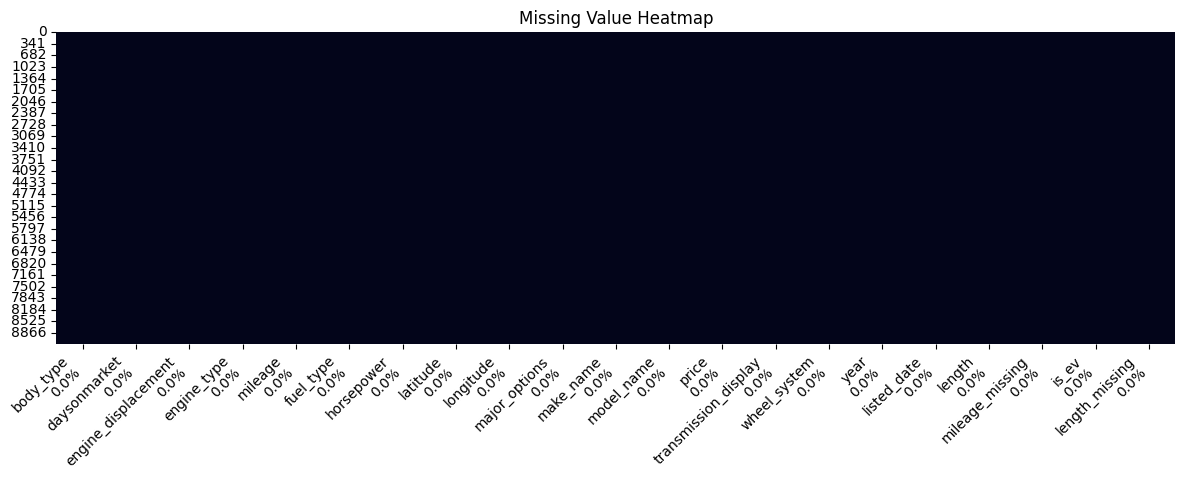

In [6]:
# --- Muutetaan Polars → Pandas vain heatmapin ajaksi ---
pdf = df.to_pandas()

missing_pct = (pdf.isnull().mean() * 100).round(2)

plt.figure(figsize=(12,5))
ax = sns.heatmap(pdf.isnull(), cbar=False)

# lisää prosentit x‑akselin labeleihin
new_labels = [
    f"{col}\n{missing_pct[col]}%" for col in pdf.columns
]

ax.set_xticklabels(new_labels, rotation=45, ha="right")
plt.title("Missing Value Heatmap")
plt.tight_layout()
plt.show()

# --- Palautetaan Pandas → Polars ---
df = pl.from_pandas(pdf)

In [7]:
df.describe()

pdf = df.to_pandas()
pdf.info()
df = pl.from_pandas(pdf)

<class 'pandas.DataFrame'>
RangeIndex: 9201 entries, 0 to 9200
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   body_type             9201 non-null   str           
 1   daysonmarket          9201 non-null   int64         
 2   engine_displacement   9201 non-null   float64       
 3   engine_type           9201 non-null   str           
 4   mileage               9201 non-null   float64       
 5   fuel_type             9201 non-null   str           
 6   horsepower            9201 non-null   float64       
 7   latitude              9201 non-null   float64       
 8   longitude             9201 non-null   float64       
 9   major_options         9201 non-null   str           
 10  make_name             9201 non-null   str           
 11  model_name            9201 non-null   str           
 12  price                 9201 non-null   float64       
 13  transmission_display  9201 no

### Varuste-flagien lisääminen
22 tärkeintä varustetta valittu esiintymisen ja toiminnallisuuden perusteella

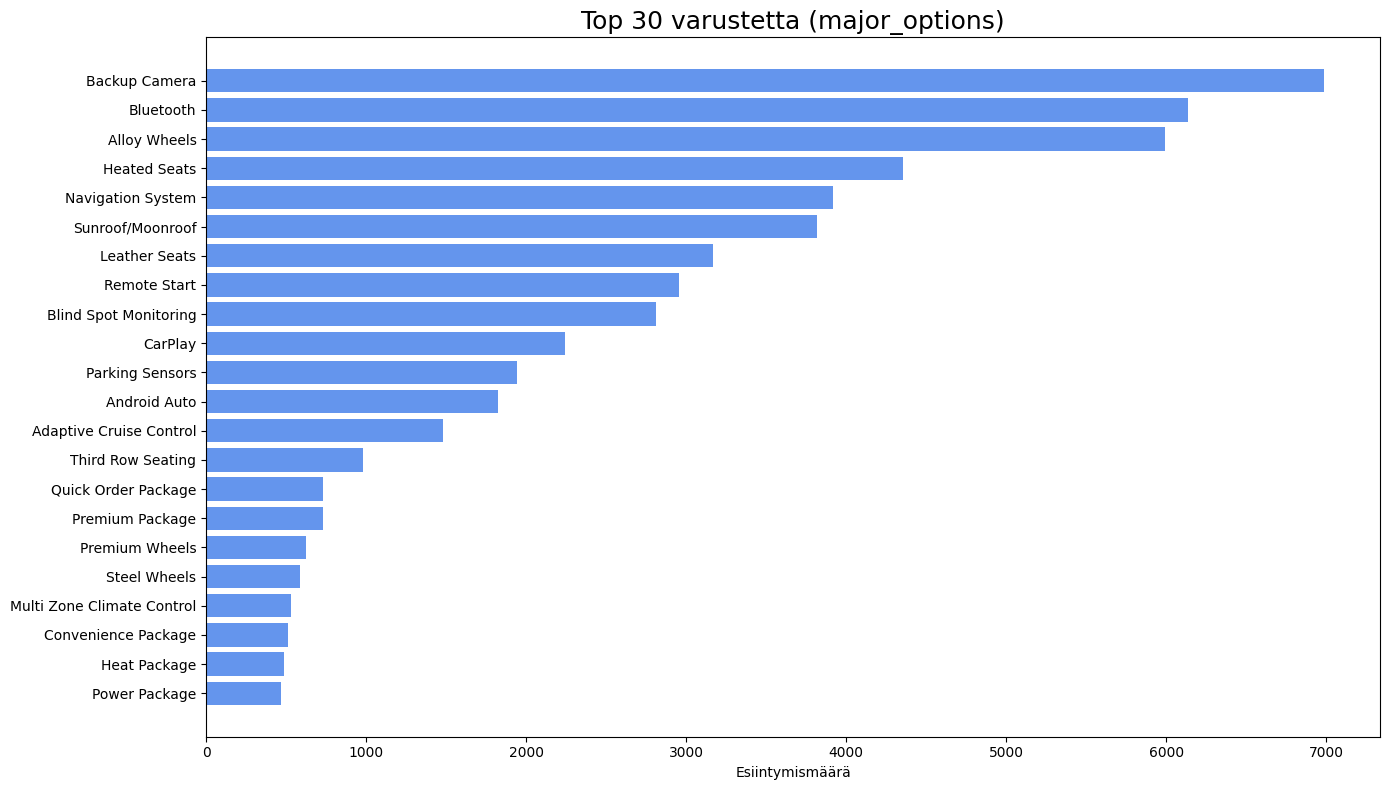

9201

In [8]:
# Pilkotaan varusteet listaksi
df_options = (
    df.select(
        pl.col("major_options")
            .str.replace_all(r"\[|\]|'", "")     # poista hakasulkeet ja ' merkit
            .str.split(",")                      # pilko listaksi
            .list.explode()                      # yksi varuste per rivi
            .str.strip_chars()                   # trimmaa whitespace
            .alias("option")
    )
    .group_by("option")
    .len()
    .sort("len", descending=True)
).to_pandas()

# df_options on jo Pandas-DataFrame, käytetään sellaisenaan
pdf = df_options.copy()

# Poistetaan tyhjät rivit
pdf = pdf[pdf['option'].notna() & (pdf['option'] != '')]

# Otetaan top 30
pdf_top = pdf.head(22)

plt.figure(figsize=(14, 8))
plt.barh(pdf_top["option"], pdf_top["len"], color="cornflowerblue")
plt.gca().invert_yaxis()
plt.title("Top 30 varustetta (major_options)", fontsize=18)
plt.xlabel("Esiintymismäärä")
plt.tight_layout()
plt.show()

df.height   



In [9]:
feature_map = {
    # ══════ Perusvarusteet (TOP 12) ══════
    "opt_backup_camera":      ["Backup Camera", "Rearview Camera"],
    "opt_bluetooth":          ["Bluetooth"],
    "opt_alloy_wheels":       ["Alloy Wheels"],
    "opt_heated_seats":       ["Heated Seats"],
    "opt_navigation":         ["Navigation System", "Navigation"],
    "opt_sunroof":            ["Sunroof", "Moonroof"],
    "opt_remote_start":       ["Remote Start"],
    "opt_carplay":            ["CarPlay"],
    "opt_android_auto":       ["Android Auto"],
    "opt_leather_seats":      ["Leather Seats"],
    "opt_blind_spot":         ["Blind Spot"],
    "opt_parking_sensors":    ["Parking Sensors", "Park Assist"],

    # ══════ Turvallisuus / ajaminen ══════
    "opt_adaptive_cruise":    ["Adaptive Cruise"],
    "opt_lane_departure":     ["Lane Departure"],
    "opt_cross_traffic":      ["Cross-Traffic"],
    "opt_third_row":          ["Third Row"],
    "opt_tow_package":        ["Tow Package"],

    # ══════ Mukavuus / premium ══════
    "opt_multi_zone":         ["Multi Zone Climate"],
    "opt_premium_audio":      ["Premium Audio", "Bose", "Harman", "Meridian"],
    "opt_cold_weather":       ["Cold Weather Package"],
    "opt_heat_package":       ["Heat Package"],
    "opt_off_road":           ["Off Road Package"],
}

exprs = []

# Luodaan flagit
for col_name, patterns in feature_map.items():
    e = pl.lit(False)
    for p in patterns:
        e = e | pl.col("major_options").str.contains(p, literal=False)
    exprs.append(e.cast(pl.Int8).alias(col_name))

df = df.with_columns(exprs)

print("Lisätty varusteflagit:", list(feature_map.keys()))

df.height

Lisätty varusteflagit: ['opt_backup_camera', 'opt_bluetooth', 'opt_alloy_wheels', 'opt_heated_seats', 'opt_navigation', 'opt_sunroof', 'opt_remote_start', 'opt_carplay', 'opt_android_auto', 'opt_leather_seats', 'opt_blind_spot', 'opt_parking_sensors', 'opt_adaptive_cruise', 'opt_lane_departure', 'opt_cross_traffic', 'opt_third_row', 'opt_tow_package', 'opt_multi_zone', 'opt_premium_audio', 'opt_cold_weather', 'opt_heat_package', 'opt_off_road']


9201

### Varusteflagien korrelaatio-heatmap

Varusteflageissa näkyy kolme selkeää ryhmää:
(1) modernit infotainment‑varusteet (CarPlay–Android Auto, r=0.92),
(2) premium‑varusteet (leather seats, heated seats, sunroof, navigation; r≈0.4),
(3) turvallisuus‑/ajoturva‑varusteet (blind spot, parking sensors, backup camera; r≈0.3).

Korrelaatiot näyttävät, että osa varusteista esiintyy samoissa autoissa hieman tavallista useammin (esim. lämmitettävät penkit ja nahkaverhoilu), mutta mikään varuste ei kulje toisen mukana niin vahvasti, että ne olisivat käytännössä sama asia.

Tämä on hyvä merkki: se tarkoittaa, että jokainen varusteflagi tuo mallille omaa erillistä lisätietoa, eikä mukana ole päällekkäisiä tai turhia varusteita. Eli nämä varusteet antavat mallille oikeaa hyödyllistä signaalia, eivät pelkkää kohinaa tai “melua”.

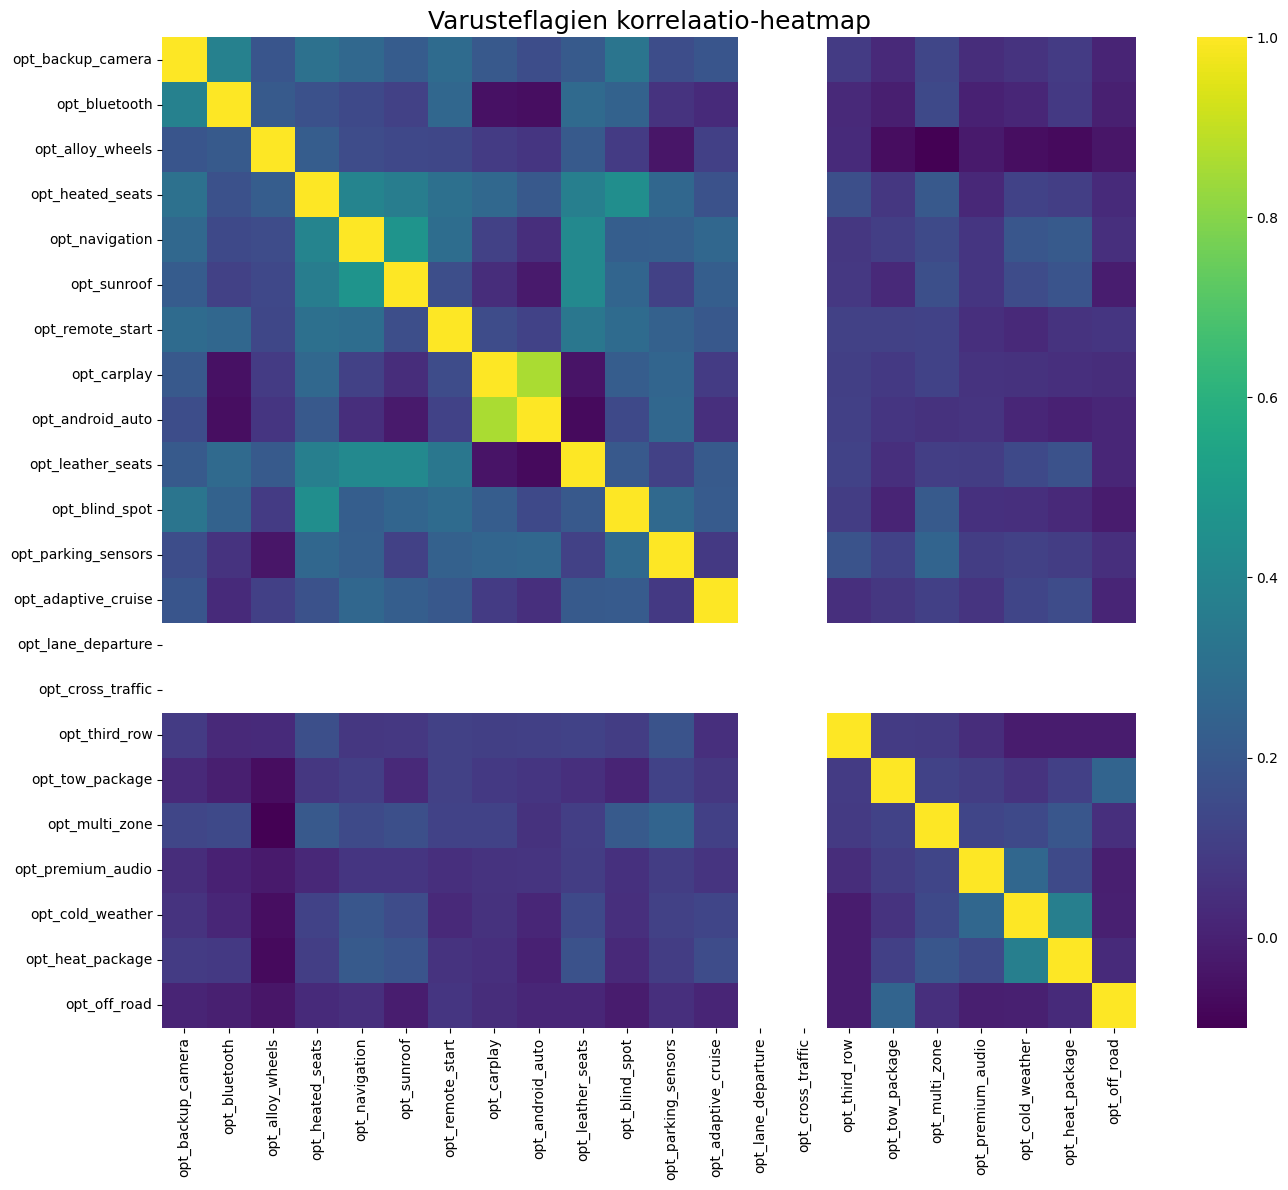

In [10]:

flag_cols = [col for col in df.columns if col.startswith("opt_")]

pdf_flags = df[flag_cols].to_pandas()

plt.figure(figsize=(14, 12))
sns.heatmap(pdf_flags.corr(), cmap="viridis", annot=False)
plt.title("Varusteflagien korrelaatio-heatmap", fontsize=18)
plt.tight_layout()
plt.show()


### Vaihteistoryhmittely (trans_group = Manual/Dual Clutch/CVT/Automatic)

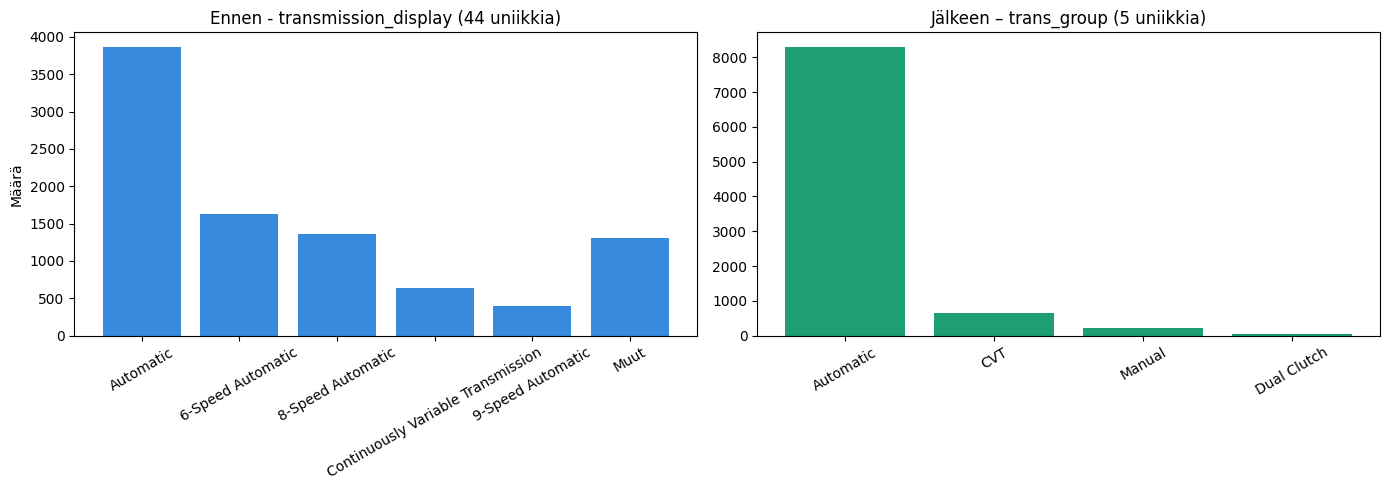

In [11]:
# ══════ Ryhmitellään 44 vaihteistotyyppiä 5 pääkategoriaan tekstihaun perusteella ══════

df = df.with_columns(
    pl.when(pl.col("transmission_display").str.contains("Manual", literal=False))
        .then(pl.lit("Manual"))
    .when(pl.col("transmission_display").str.contains("Dual Clutch", literal=False))
        .then(pl.lit("Dual Clutch"))
    .when(
        # CVT tunnetaan kahdella eri nimellä
        pl.col("transmission_display").str.contains("Continuously Variable", literal=False)
        | pl.col("transmission_display").str.contains("CVT", literal=False)
    )
        .then(pl.lit("CVT"))
    .when(pl.col("transmission_display").str.contains("Automatic", literal=False))
        .then(pl.lit("Automatic"))
    .otherwise(pl.lit("Unknown"))  # ei osuttu mihinkään kategoriaan
    .alias("trans_group")
)


# ══════ Vaihteistoryhmittelyn vaikutus - ennen ja jälkeen ══════

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ennen - otetaan top 5 ja loput yhdistetään "Muut"-kategoriaan
before = df["transmission_display"].value_counts().sort("count", descending=True).to_pandas()
before_top = before.head(5)
other = before.iloc[5:]["count"].sum()
before_plot = list(before_top["transmission_display"]) + ["Muut"]
before_vals = list(before_top["count"]) + [other]

axes[0].bar(before_plot, before_vals, color="#378ADD")
axes[0].set_title("Ennen - transmission_display (44 uniikkia)")
axes[0].set_ylabel("Määrä")
axes[0].tick_params(axis="x", rotation=30)

# Jälkeen - kaikki 5 ryhmää näkyviin sellaisenaan
after = df["trans_group"].value_counts().sort("count", descending=True).to_pandas()
axes[1].bar(after["trans_group"], after["count"], color="#1D9E75")
axes[1].set_title("Jälkeen – trans_group (5 uniikkia)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Kausiryhmittelyt

listed_date painottuu vuoteen 2020

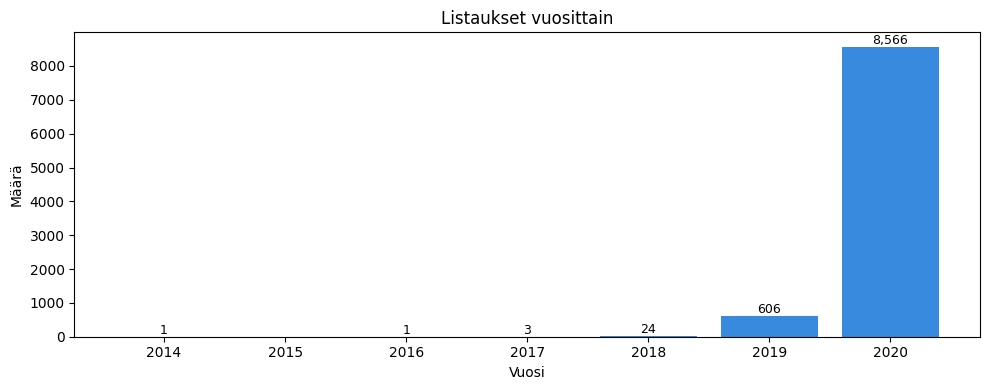

In [12]:
year_counts = (
    df.with_columns(
        pl.col("listed_date").dt.year().alias("listed_year")
    )
    .group_by("listed_year")
    .agg(pl.len().alias("count"))
    .sort("listed_year")
    .to_pandas()
)

plt.figure(figsize=(10, 4))
bars = plt.bar(year_counts["listed_year"], year_counts["count"], color="#378ADD")
plt.title("Listaukset vuosittain")
plt.xlabel("Vuosi")
plt.ylabel("Määrä")

# Lukema jokaisen pylvään yläpuolelle
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center", va="bottom", fontsize=9
    )

plt.tight_layout()
plt.show()

In [13]:
df = df.with_columns([
    # ══════ Vuodenaika kuukauden perusteella ══════
    pl.when(pl.col("listed_date").dt.month().is_in([12, 1, 2]))
        .then(pl.lit("Winter"))
    .when(pl.col("listed_date").dt.month().is_in([3, 4, 5]))
        .then(pl.lit("Spring"))
    .when(pl.col("listed_date").dt.month().is_in([6, 7, 8]))
        .then(pl.lit("Summer"))
    .otherwise(pl.lit("Fall"))
        .alias("listed_season"),

    # ══════ Kuukausi (1–12) ══════
    pl.col("listed_date").dt.month().alias("listed_month"),

    # ══════ Viikonpäivä (ma=0 ... su=6) ══════
    pl.col("listed_date").dt.weekday().alias("listed_weekday"),

    # ══════ Viikonloppu (la=5, su=6 → 1, muut → 0) ══════
    pl.when(pl.col("listed_date").dt.weekday().is_in([5, 6]))
        .then(pl.lit(1))
        .otherwise(pl.lit(0))
        .alias("is_weekend"),
])

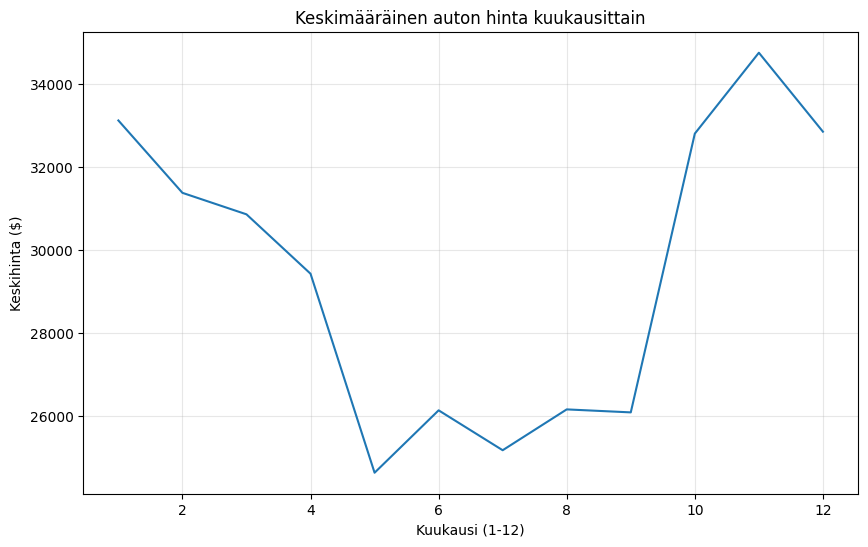

In [14]:

# Polars → Pandas
pdf = df.select(["listed_month", "price"]).to_pandas()

plt.figure(figsize=(10,6))
sns.lineplot(
    data=pdf,
    x="listed_month",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Keskimääräinen auton hinta kuukausittain")
plt.xlabel("Kuukausi (1-12)")
plt.ylabel("Keskihinta ($)")
plt.grid(alpha=0.3)
plt.show()


# Polars -> Pandas
pdf = df.to_pandas()

### Muut ryhmittelyt

In [15]:
# ══════ km_per_year – ajetut kilometrit suhteessa auton ikään ══════
# Jakamalla mileage auton iällä saadaan vuosittainen ajosuorite clip(lower_bound=1) estää jaon nollalla uusilla autoilla (listed_date.year == year)
df = df.with_columns([
    (pl.col("mileage") /
        (pl.col("listed_date").dt.year() - pl.col("year"))
          .clip(lower_bound=1)  # estää jakamisen nollalla
    ).alias("km_per_year")
])


# ══════ hp_per_liter (hv per litra) ══════
df = df.with_columns([
    (pl.col("horsepower") / pl.col("engine_displacement"))
        .alias("hp_per_liter")
])

# ══════ power_density (hv per pituusyksikkö) ══════
# Varmistetaan että length on numeerinen
df = df.with_columns([
    pl.col("length")
        .cast(pl.Utf8)
        .str.replace_all(r"[^0-9.]", "") # jätetään vain numerot ja piste
        .replace("", None) # tyhjät stringit → NULL
        .cast(pl.Float64)
        .alias("length")
])

df = df.with_columns([
    (pl.col("horsepower") / pl.col("length"))
        .alias("power_density")
])


# ══════ age_bin - auton ikä luokiteltuna ══════
df = df.with_columns([
    (pl.col("listed_date").dt.year() - pl.col("year")).alias("car_age")
])

df = df.with_columns([
    pl.when(pl.col("car_age") <= 3)
        .then(pl.lit("0-3v"))
    .when(pl.col("car_age") <= 5)
        .then(pl.lit("3-5v"))
    .when(pl.col("car_age") <= 8)
        .then(pl.lit("5-8v"))
    .otherwise(pl.lit("8+v"))
    .alias("age_bin")
])

# ══════ mileage_bin - kilometrit luokiteltuna ══════
df = df.with_columns([
    pl.when(pl.col("mileage") <= 15_000)
        .then(pl.lit("0-15k"))
    .when(pl.col("mileage") <= 50_000)
        .then(pl.lit("15k-50k"))
    .when(pl.col("mileage") <= 100_000)
        .then(pl.lit("50k-100k"))
    .otherwise(pl.lit("100k+"))
    .alias("mileage_bin")
])

# ══════ options_count - varusteiden määrä ══════
# Lasketaan pilkkujen määrä + 1 = varusteiden lukumäärä
# Tyhjä lista "[]" saa arvon 0
df = df.with_columns([
    pl.when(pl.col("major_options") == "[]")
        .then(pl.lit(0))
        .otherwise(pl.col("major_options").str.count_matches(",").add(1))
        .alias("options_count")
])

# ══════ luxury_brands - Luxury‑merkit ══════


luxury_brands = [
    "Audi",
    "BMW",
    "Mercedes-Benz",
    "Lexus",
    "Porsche",
    "Jaguar",
    "Land Rover",
    "Volvo",
    "Tesla",
    "Rolls-Royce",
    "Bentley",
    "Maserati",
    "Alfa Romeo",
    "Genesis",
    "Cadillac",
    "Lincoln",
    "Acura",
    "Infiniti",
]


df = df.with_columns([
    pl.col("make_name")
      .is_in(luxury_brands)
      .cast(pl.Int8)
      .alias("luxury_flag")
])

df.height

9201

### Korrelaatioheatmap uusille teknisille featureille

Tehoon ja moottoriin liittyvät tekniset featuret selittävät auton hintaa vahvasti (horsepower, power_density), mutta eivät juuri myyntiajan vaihtelua. Sen sijaan kilometrit ja ajotahti (km_per_year) korreloivat selvästi hinnan laskun kanssa ja varusteiden määrä nostaa hintaa odotetusti. 

Myyntiaika on teknisille featureille vain heikosti lineaarinen ilmiö, mikä sopii yhteen markkinadynamiikan kanssa: myyntiaika määräytyy enemmän hinnoittelun, kysynnän ja makrotekijöiden mukaan kuin auton fyysisten ominaisuuksien.

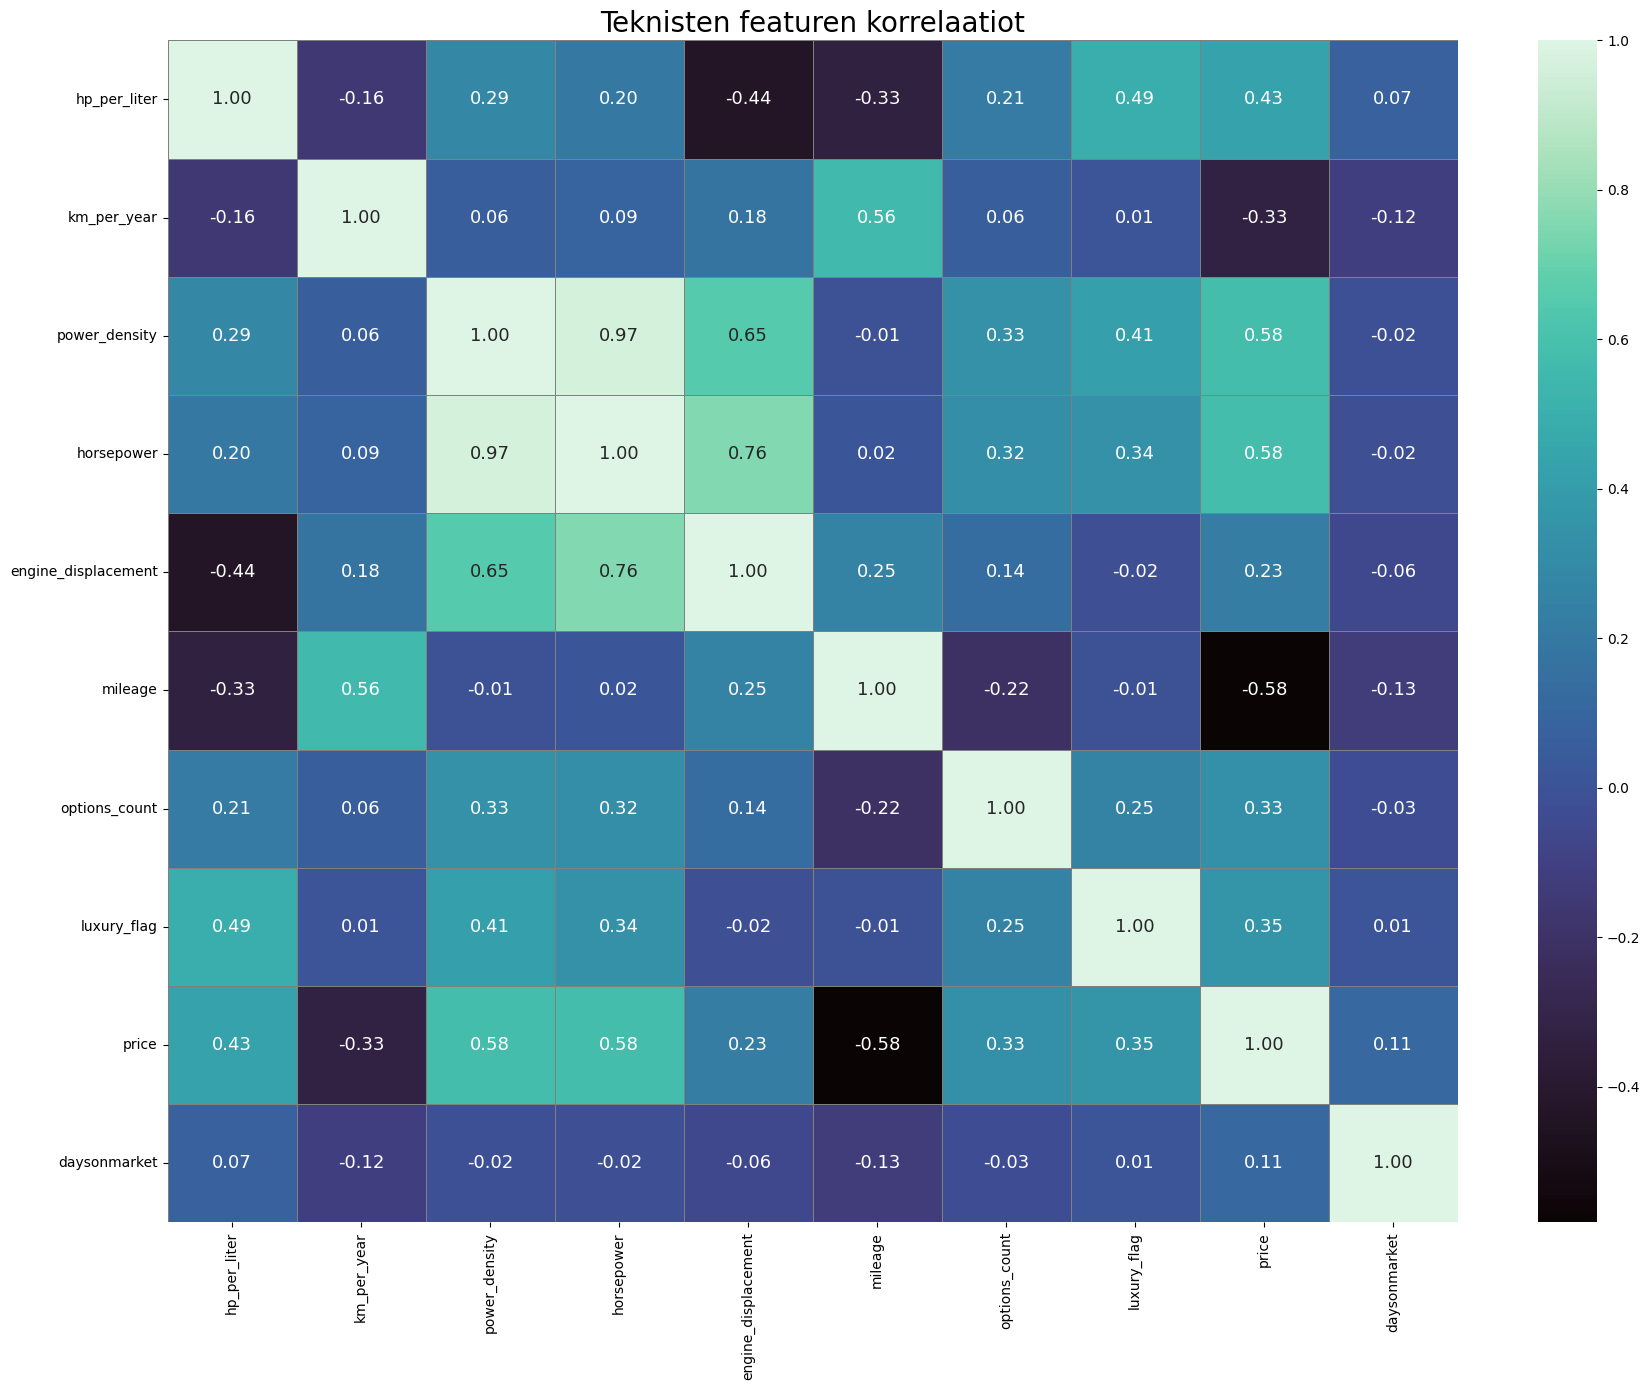

In [16]:
cols = [
    "hp_per_liter",
    "km_per_year",
    "power_density",
    "horsepower",
    "engine_displacement",
    "mileage",
    "options_count",
    "luxury_flag",
    "price",
    "daysonmarket"
]

plt.figure(figsize=(18, 14))
sns.heatmap(
    df.select(cols).to_pandas().corr(),
    annot=True,
    cmap="mako",
    fmt=".2f",
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"size": 13}
)
plt.title("Teknisten featuren korrelaatiot", fontsize=20)
plt.tight_layout()
plt.show()

### Premium vs non‑premium vertailu (luxury_flag → price)

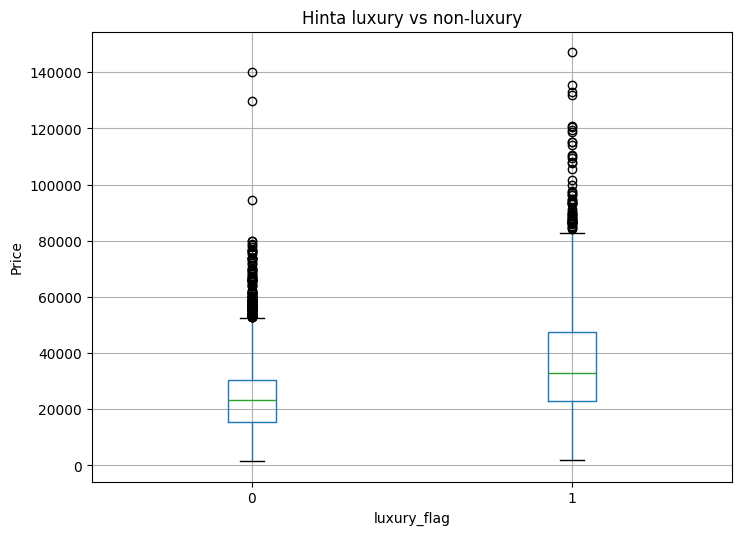

(9201, 56)

In [17]:
df.to_pandas().boxplot(column="price", by="luxury_flag", figsize=(8,6))
plt.title("Hinta luxury vs non-luxury")
plt.suptitle("")
plt.xlabel("luxury_flag")
plt.ylabel("Price")
plt.show()

df.shape

### Geo-featuret

In [18]:
# Muutetaan Polars -> Pandas, koska geopandas tarvitsee Pandasia
pdf = df.to_pandas()
gdf = gpd.GeoDataFrame(
    pdf,
    geometry=gpd.points_from_xy(pdf["longitude"], pdf["latitude"]),
    crs="EPSG:4326"
)
# Ladataan USA:n piirikuntageometriat
counties = gpd.read_file(DATA_PATH / "cb_2023_us_county_500k")[["GEOID", "NAME", "STATEFP", "geometry"]]
counties = counties.to_crs(gdf.crs)

# Spatial join (etäisyys = sisällä oleva piste)
gdf = gpd.sjoin(gdf, counties, how="left", predicate="within").drop(columns="index_right")

# Poistetaan US-territoriot (ei kuulu 50 osavaltioon)
territories = ["60", "66", "69", "72", "74", "78"]
gdf = gdf[~gdf["STATEFP"].isin(territories)]

# Poistetaan rivit joita ei saatu joinattua mihinkään countyyn
before = len(gdf)
gdf = gdf.dropna(subset=["GEOID"])
after = len(gdf)
removed = before - after

print(f"Poistettu rivejä: {removed:,}")
print(f"Rivejä joinin jälkeen: {len(gdf):,}")
print(f"Uniikkeja GEOID-piirikuntia: {gdf['GEOID'].nunique()}")
print(f"Uniikkeja osavaltioita: {gdf['STATEFP'].nunique()}")

# Palataan Polarsiin - geometry-sarake poistetaan
df = pl.from_pandas(gdf.drop(columns="geometry"))
print("Geotiedot lisätty (GEOID, NAME, STATEFP)")



Poistettu rivejä: 0
Rivejä joinin jälkeen: 9,098
Uniikkeja GEOID-piirikuntia: 32
Uniikkeja osavaltioita: 5
Geotiedot lisätty (GEOID, NAME, STATEFP)


### Bensahintojen hakeminen ja liittäminen autolistings‑dataan (EIA API v2)

EIA = U.S. Energy Information Administration.

Yhdysvaltojen virallinen energia‑ ja polttoainehintojen datalähde

-> Joinissa käytettävä arvo on käytännössä kyseisen kuukauden VIIMEIN viikkohinta.

In [ ]:
# Haetaan EIA API -avain ympäristömuuttujasta (.env). Avaimen saa tehtyä itselle rekisteröitymällä https://www.eia.gov/opendata/register.php
API_KEY = os.getenv("EIA_API_KEY")

# Series ID: Yhdysvaltain keskihinta Regular Gasoline, viikkotasolla ($/gallon)
series_id = "PET.EMM_EPMR_PTE_NUS_DPG.W"

url = f"https://api.eia.gov/v2/seriesid/{series_id}?api_key={API_KEY}"

r = requests.get(url).json()
print("API keys:", r.keys())
data = r["response"]["data"]
df_gas = pd.DataFrame(data)

# Muutetaan hintasarake (value) float-muotoon
df_gas["gas_price"] = df_gas["value"].astype(float)

# Muutetaan API:n period-merkkijono datetime-muotoon
df_gas["date"] = pd.to_datetime(df_gas["period"])

# Luodaan kuukausitaso (kuukauden 1. päivä) joinia varten
df_gas["month_start"] = df_gas["date"].dt.to_period("M").dt.to_timestamp()


# Muutetaan bensadata Polars DataFrameksi ja castataan datetime[ms]-formaattiin
gas_pl = (
    pl.from_pandas(df_gas[["month_start", "gas_price"]])
      .with_columns(
          pl.col("month_start").cast(pl.Datetime("ms"))
      )
)


# ══════ Joinataan auto-dataan ══════

# Luodaan auto-dataan yhteensopiva month_start (kuukauden alku)
df = df.with_columns(
    pl.col("listed_date")
      .dt.truncate("1mo") # pyöristetään kuukauden alkuun
      .cast(pl.Datetime("ms")) # sama tarkkuus kuin gas_pl
      .alias("month_start")
)

# Joinataan bensahinta jokaiselle autolle sen listauskuukauden mukaan

# Huom: gas_pl sisältää useita rivejä jokaiselle kuukaudelle (viikkohinnat), ja koska niitä EI ole aggregoitu, Polarsin join valitsee näistä käytännössä viimeisen viikkohinnan per kuukausi joinin tulokseksi
df = df.join(gas_pl, on="month_start", how="left")


# Nollataan gas_price sähköautoilta
df = df.with_columns(
    pl.when(pl.col("is_ev") == 1) # käytetään aiemmin luotua flagia
      .then(0.0)
      .otherwise(pl.col("gas_price"))
      .alias("gas_price")
)

df.head()
df.shape


### USA:n bensiinin hinta myyntidatan kattamalta ajalta (EIA)

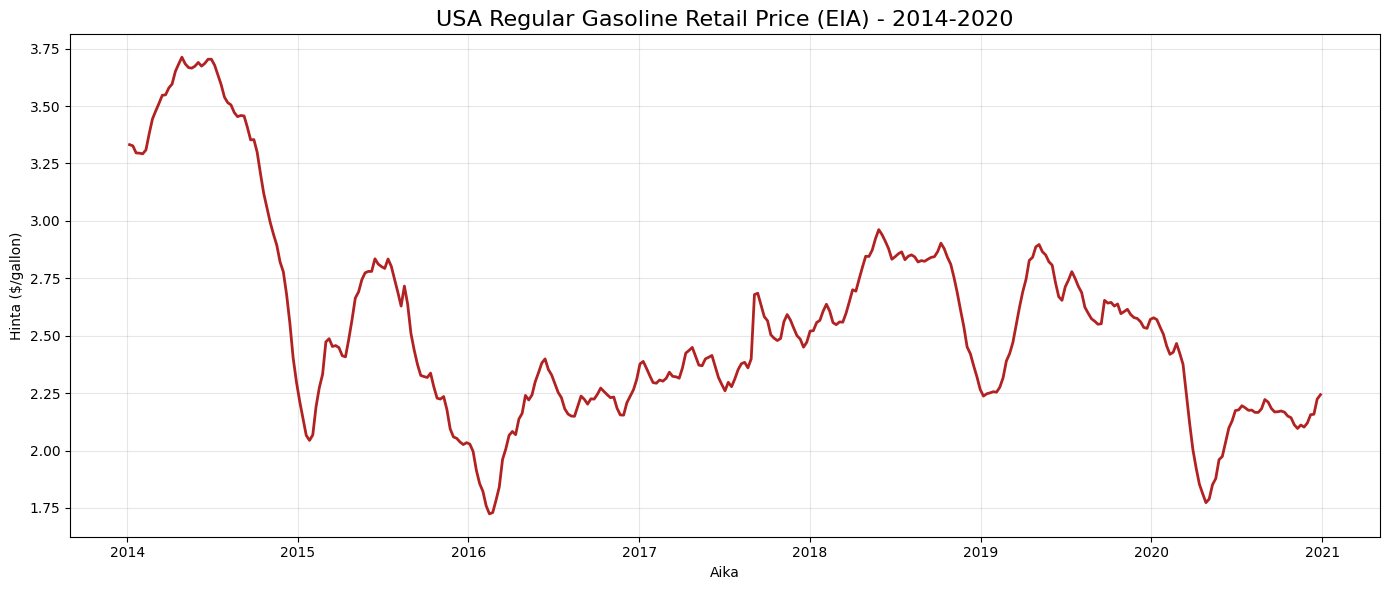

In [20]:
# Haetaan myyntidatan aikaväli (min/max vuodet) 
min_year = df.select(pl.col("listed_date").dt.year().min()).item()
max_year = df.select(pl.col("listed_date").dt.year().max()).item()

# Tehdään kopio bensiinidatasta piirtämistä varten
df_b = df_gas.copy()
df_b["gas_price"] = df_b["value"].astype(float)     # muutetaan hinta floattiin
df_b["date"] = pd.to_datetime(df_b["period"])       # muutetaan period -> datetime

# Rajataan bensiinidatan aikajänne samoihin vuosiin kuin myyntidata -> ei näytä bensahinta-aikasarjan ulkopuolisia vuosia
df_b = df_b[(df_b["date"].dt.year >= min_year) & (df_b["date"].dt.year <= max_year)]


plt.figure(figsize=(14, 6))
plt.plot(df_b["date"], df_b["gas_price"], color="firebrick", linewidth=2)

plt.title(f"USA Regular Gasoline Retail Price (EIA) - {min_year}-{max_year}", fontsize=16)
plt.xlabel("Aika")
plt.ylabel("Hinta ($/gallon)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Bensiinin hinta -korrelaatiot

Bensiinin hinnan ja myyntiajan välinen 0.62 korrelaatio osoittaa vahvan yhteyden: korkeampi bensa -> pidempi myyntiaika.

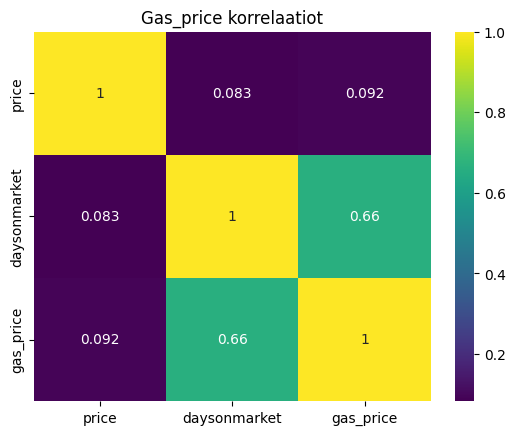

In [21]:
cols = ["price", "daysonmarket", "gas_price"]
sns.heatmap(df.select(cols).to_pandas().corr(), annot=True, cmap="viridis")
plt.title("Gas_price korrelaatiot")
plt.show()

In [22]:
pdf = df.to_pandas()
pdf.info()
df = pl.from_pandas(pdf)

<class 'pandas.DataFrame'>
RangeIndex: 41018 entries, 0 to 41017
Data columns (total 61 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   body_type             41018 non-null  str           
 1   daysonmarket          41018 non-null  int64         
 2   engine_displacement   41018 non-null  float64       
 3   engine_type           41018 non-null  str           
 4   mileage               41018 non-null  float64       
 5   fuel_type             41018 non-null  str           
 6   horsepower            41018 non-null  float64       
 7   latitude              41018 non-null  float64       
 8   longitude             41018 non-null  float64       
 9   major_options         41018 non-null  str           
 10  make_name             41018 non-null  str           
 11  model_name            41018 non-null  str           
 12  price                 41018 non-null  float64       
 13  transmission_display  41018

In [23]:
df = df.drop([
    #"listed_date", # tarvitaan splitissä
    "transmission_display", # korvattu trans_group:lla
    "length", # käytetty power_density
    "major_options", # string, korvattu opt_* varuste-flageilla
    "NAME", # county-nimi ei hyödytä mallia
    "month_start", # bensiinin hinnan joinin apukenttä
])

In [24]:
# Poista inf-arvot (muuta ne Nulliksi), ongelma vanhassa koodissa datetime-tyyppi
# listed_date kentässä

float_cols = [
    c for c, dtype in zip(df.columns, df.dtypes)
    if dtype in (pl.Float32, pl.Float64)
]

df = df.with_columns([
    pl.when(pl.col(c).is_infinite())
      .then(None)
      .otherwise(pl.col(c))
      .alias(c)
    for c in float_cols
])

df = df.fill_null(0)


### Tässä split, kielimallin mukaan oikea järjestys


RAW DATA
   │
   ├── 1. time split (listing_date)
   │        ├── train_df
   │        └── test_df
   │
   ├── 2A. CatBoost → EI encodingia
   │
   └── 2B. XGB/LGBM → encoding TRAINISTA
                ↓
        sama mapping TESTIIN

In [25]:
df = df.sort("listed_date")

split_date = df["listed_date"].quantile(0.8) #eli jako 80/20

train_df = df.filter(pl.col("listed_date") <= split_date).drop("listed_date")#listed_datea ei tarvita enään
test_df  = df.filter(pl.col("listed_date") > split_date).drop("listed_date")

In [26]:
# ══════ VAIHE 1: Aggregaatit (ennen X/y-jakoa) ══════

# brand_model molempiin
train_df = train_df.with_columns(
    pl.concat_str(["make_name", "model_name"], separator="_").alias("brand_model")
)
test_df = test_df.with_columns(
    pl.concat_str(["make_name", "model_name"], separator="_").alias("brand_model")
)

# LOO-featuret trainiin (targetit vielä mukana — oikein)
train_df = train_df.with_columns([
    pl.when(pl.col("price").count().over("GEOID") > 1)
      .then((pl.col("price").sum().over("GEOID") - pl.col("price")) /
            (pl.col("price").count().over("GEOID") - 1))
      .otherwise(None).alias("county_avg_price"),

    pl.when(pl.col("daysonmarket").count().over("GEOID") > 1)
      .then((pl.col("daysonmarket").sum().over("GEOID") - pl.col("daysonmarket")) /
            (pl.col("daysonmarket").count().over("GEOID") - 1))
      .otherwise(None).alias("county_avg_dom"),

    pl.when(pl.col("price").count().over("brand_model") > 1)
      .then((pl.col("price").sum().over("brand_model") - pl.col("price")) /
            (pl.col("price").count().over("brand_model") - 1))
      .otherwise(None).alias("brand_model_avg_price"),

    pl.when(pl.col("daysonmarket").count().over("make_name") > 1)
      .then((pl.col("daysonmarket").sum().over("make_name") - pl.col("daysonmarket")) /
            (pl.col("daysonmarket").count().over("make_name") - 1))
      .otherwise(None).alias("brand_avg_dom"),

    pl.when(pl.col("daysonmarket").count().over(["make_name", "model_name"]) > 1)
      .then((pl.col("daysonmarket").sum().over(["make_name", "model_name"]) - pl.col("daysonmarket")) /
            (pl.col("daysonmarket").count().over(["make_name", "model_name"]) - 1))
      .otherwise(None).alias("model_avg_dom"),
])

# Globaalit aggregaatit testidataa varten (lasketaan train_df:stä)
county_agg = train_df.group_by("GEOID").agg([
    pl.col("price").mean().alias("county_avg_price"),
    pl.col("daysonmarket").mean().alias("county_avg_dom"),
])
brand_model_agg = train_df.group_by("brand_model").agg(
    pl.col("price").mean().alias("brand_model_avg_price")
)
model_avg_km = train_df.group_by(["make_name", "model_name"]).agg(
    pl.col("mileage").mean().alias("model_avg_km")
)
brand_avg_dom = train_df.group_by("make_name").agg(
    pl.col("daysonmarket").mean().alias("brand_avg_dom")
)
model_avg_dom = train_df.group_by(["make_name", "model_name"]).agg(
    pl.col("daysonmarket").mean().alias("model_avg_dom")
)

# Joinnit testidataan
test_df = (test_df
    .join(county_agg,      on="GEOID",                    how="left")
    .join(brand_model_agg, on="brand_model",               how="left")
    .join(model_avg_km,    on=["make_name", "model_name"], how="left")
    .join(brand_avg_dom,   on="make_name",                 how="left")
    .join(model_avg_dom,   on=["make_name", "model_name"], how="left")
)

# model_avg_km myös trainiin (ei LOO-versiota tälle)
train_df = train_df.join(model_avg_km, on=["make_name", "model_name"], how="left")

# Pudota brand_model vasta tässä
train_df = train_df.drop("brand_model")
test_df  = test_df.drop("brand_model")



In [27]:
#tehdään mapping trainista




1. split train/test
2. tee encoding TRAIN-datan perusteella
3. sovella sama mapping TEST-dataan

### Label-enkoodaus kategorisille muuttujille

| Malli    | Label encoding OK?                        | Parempi tapa        |
| -------- | ----------------------------------------- | ------------------- |
| XGBoost  | ✅ kyllä                                   | usein OK            |
| LightGBM | ⚠️ vain jos ilmoitat categorical featuret | native categorical  |
| CatBoost | ❌ EI suositeltu                           | anna raw kategoriat |

CatBoost dataset
df_catboost = df.clone()   # EI encodingia

XGBoost / LightGBM dataset
df_encoded = df.with_columns([
    pl.col(col).cast(pl.Categorical).to_physical().alias(col)
    for col in categorical_cols
])


# Lista sarakkeista, jotka muutetaan kategorisista numeerisiksi
categorical_cols = [
    # Perus kategoriat
    "make_name",
    "model_name",
    "body_type",
    "engine_type",
    "fuel_type",
    "wheel_system",
    "trans_group",
    "listed_season",
    "listed_month",
    "listed_weekday", 
    "age_bin",
    "mileage_bin",
    "GEOID",
    "STATEFP",
]

# Muutetaan kukin sarake:
# 1) Categorical-tyyppiin (sisäinen kategoriataulukko)
# 2) to_physical(): palauttaa kategorian numeerisen id-koodin (int)
# -> eli label encoding
df = df.with_columns([
    pl.col(col).cast(pl.Categorical).to_physical().alias(col)
    for col in categorical_cols
])



#df_info()



### Poistetaan tarpeettomat sarakkeet ennen splittiä

### Korjataan virheelliset äärettömät arvot: muutetaan inf → null ja täytetään 0:lla

Jos jokin laskutoimitus menee pieleen, esim. jako nollalla, syntyy inf-arvoja. Nollataan ne, jotta mallille ei päädy mahdottomia numeroita.

# 🔀 Train/test-split
Sinulla on:

price (regressio)
daysonmarket (regressio)

Tämä on multi-target regression.

Nykyinen jako — ongelma
train_test_split(pdf, ...)

Tämä:

sekoittaa ajan
aiheuttaa data leakagea

Autodata on lähes aina ajallinen prosessi.

👉 Tulevaisuutta ei saa käyttää menneisyyden ennustamiseen.

Oikea tapa: Time-based split

Koska sinulla on:

listed_month
listed_season

(tai toivottavasti päivämäärä)

tee:

df = df.sort("listing_date")

split_date = df["listing_date"].quantile(0.8)

train_df = df.filter(pl.col("listing_date") <= split_date)
test_df  = df.filter(pl.col("listing_date") > split_date)


Miksi tämä on kriittistä?

Random split antaa epärealistisen hyvän tuloksen, koska:

sama markkinatilanne näkyy train + test
fuel prices leakage
seasonal effects leakkaavat

Oikeassa maailmassa ennustetaan tulevaa dataa.

**🔥 Pitääkö tehdä kaksi datasettiä?**

EI.

Tee:

X = features
y_price
y_days

Miksi kaksi mallia?

Tree boosting ei oikeasti tee multi-output regressiota hyvin.

Parempi:

price_model.fit(X_train, y_price_train)
dom_model.fit(X_train, y_dom_train)

✅ 3. Pitääkö skaalata?

Lyhyt vastaus:

❌ EI tarvitse.

Miksi?

Tree-based mallit eivät käytä etäisyyksiä.

Ne tekevät:

feature < threshold ?

ei:

distance(feature)

**Milloin skaalaus voi auttaa vähän?**

Harvinaiset tilanteet:

erittäin vinot jakaumat
log(price) target transformation

👉 Tämä on oikeasti hyödyllinen.

Suositus:
df = df.with_columns(
    pl.col("price").log1p().alias("price_log")
)


**miksi listing_date on niin keskeinen?**

Tämä on erinomainen kysymys, ja itse asiassa juuri tämä erottaa perus ML-harjoituksen oikeasta data-analytiikasta.

Lyhyt vastaus:

listing_date tekee ongelmastasi ajallisen ennustustehtävän eikä satunnaisen regressio-ongelman.

Selitän konkreettisesti, miksi se on poikkeuksellisen keskeinen juuri autojen hinnoissa ja myyntiajoissa.


✅ Vastaan alkuperäiseen kysymykseen suoraan

Miksi listing_date on keskeinen vaikka sitä ei enää ole?

Koska lähes kaikki nämä featuret ovat sen funktioita:

gas_price
car_age
listed_month
listed_season
daysonmarket

Ne kaikki kuvaavat samaa asiaa:

markkinatilanne listaushetkellä.

Siksi split pitää edelleen tehdä ajan mukaan.



In [28]:
# # GroupKFold hylättiin koska se jakaa datan niin että tietyt merkki+malli-yhdistelmät
# # ovat vain trainissa tai vain testissä - tämä tekee aggregaattifeaturesista (brand_model_avg_price,
# # model_avg_km) käyttökelvottomia testidatalle, koska ne lasketaan train-datasta eikä
# # testissä ole vastaavia yhdistelmiä. Satunnainen split on realistisempi, koska oikeassa
# # käytössä malli ennustaa tuttuja merkkejä/malleja.

# # Ryhmä = merkki + malli yhdistettynä
# df = df.with_columns(
#     pl.concat_str(
#         [pl.col("make_name"), pl.col("model_name")],
#         separator="_"
#     ).alias("brand_model")
# )

# # GroupKFold — 5 foldia = 80/20 jako
# gkf = GroupKFold(n_splits=5)

# # GroupKFold vaatii numpy-arrayn ryhmistä
# groups = df["brand_model"].to_numpy()

# # Otetaan ensimmäinen fold käyttöön
# for train_idx, test_idx in gkf.split(X=df, y=None, groups=groups):
#     train_df = df[train_idx.tolist()]
#     test_df  = df[test_idx.tolist()]
#     break

# print(f"Train: {len(train_df):,} riviä")
# print(f"Test:  {len(test_df):,} riviä")

# # Varmistetaan ettei vuotoa - pitää olla 0
# train_models = set(train_df["brand_model"].to_list())
# test_models  = set(test_df["brand_model"].to_list())
# print(f"Yhteisiä brand_model-yhdistelmiä: {len(train_models & test_models)}")

# ⚠️ Train/test-splitin jälkeen suoritettavat

### Poistetaan hinta-, kilometri- ja hevosvoimajakaumien ääripäät **ainoastaan opetusdatasta** käyttämällä 1%–99% kvanttiilejä (Tehtävä ennen aggregaatteja!)

Ei kannata poistaa kummastakaan harvinaisia mutta aitoja tapauksia. Mites ne sitten käsitellään?

In [29]:
# Tarkistetaan paljonko rivejä poistuisi eri rajoilla
for col in ["price", "mileage", "horsepower"]:
    q1 = train_df[col].quantile(0.01)
    q99 = train_df[col].quantile(0.99)
    n = train_df.filter(
        (pl.col(col) < q1) | (pl.col(col) > q99)
    ).height
    print(f"{col}: alle 1% tai yli 99% → {n:,} riviä ({n/train_df.height*100:.1f}%)")

price: alle 1% tai yli 99% → 622 riviä (1.9%)
mileage: alle 1% tai yli 99% → 333 riviä (1.0%)
horsepower: alle 1% tai yli 99% → 634 riviä (1.9%)


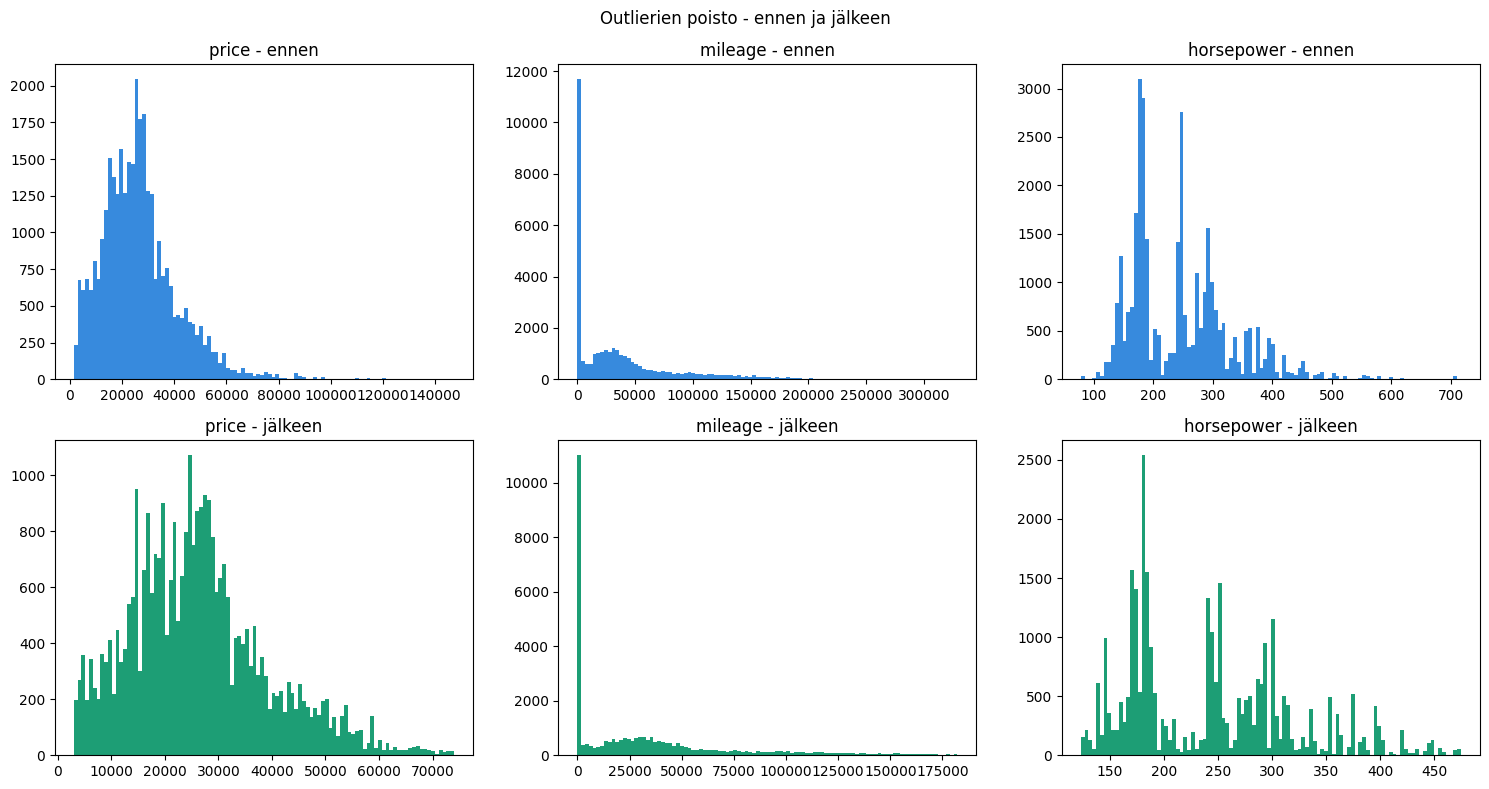

Jäljellä: 31,946 riviä


In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["price", "mileage", "horsepower"]

# Ennen outlierien poistoa
for i, col in enumerate(cols):
    axes[0, i].hist(train_df[col].to_numpy(), bins=100, color="#378ADD")
    axes[0, i].set_title(f"{col} - ennen")

# ══════ Outlierit pois (1%–99% kvanttiili) ══════
for col in cols:
    q1  = train_df[col].quantile(0.01)
    q99 = train_df[col].quantile(0.99)
    train_df = train_df.filter(pl.col(col).is_between(q1, q99))

# Jälkeen
for i, col in enumerate(cols):
    axes[1, i].hist(train_df[col].to_numpy(), bins=100, color="#1D9E75")
    axes[1, i].set_title(f"{col} - jälkeen")

plt.suptitle("Outlierien poisto - ennen ja jälkeen")
plt.tight_layout()
plt.show()
print(f"Jäljellä: {train_df.height:,} riviä")

### Lasketaan markkina-tason aggregaatit **ainoastaan opetusdatasta** ja liitetään ne sen jälkeen sekä train- että test-dataan

### Data sample

In [36]:
# ══════ Tallennetaan esikäsitelty train- ja test-data ══════
train_df.write_parquet(DATA_PATH / "train.parquet")
test_df.write_parquet(DATA_PATH / "test.parquet")
print(f"Train tallennettu: {train_df.height:,} riviä, {train_df.width} saraketta")
print(f"Test tallennettu:  {test_df.height:,} riviä, {test_df.width} saraketta")



Train tallennettu: 31,946 riviä, 61 saraketta
Test tallennettu:  7,558 riviä, 61 saraketta


### Train ja test -datan tallennus
Mallinnuksessa kannattaa tallentaa:

X (features)
y (target)

erikseen, koska:

sama X voidaan käyttää eri targeteille
price ja DOM ovat eri mallitehtäviä
vältät vahingossa target leakagea myöhemmin

data/
│
├── catboost/
│   ├── X_train.parquet
│   ├── X_test.parquet
│   ├── y_price_train.parquet
│   ├── y_price_test.parquet
│   ├── y_dom_train.parquet
│   └── y_dom_test.parquet
│
└── encoded/
    ├── X_train.parquet
    ├── X_test.parquet
    ├── y_price_train.parquet
    ├── y_price_test.parquet
    ├── y_dom_train.parquet
    └── y_dom_test.parquet


#Series to DF
y_price_train_df = y_price_train.to_frame()
y_price_test_df  = y_price_test.to_frame()

y_dom_train_df = y_dom_train.to_frame()
y_dom_test_df  = y_dom_test.to_frame()


#CatBoost datasetin mallinnus

CATBOOST_PATH = DATA_PATH / "catboost"
CATBOOST_PATH.mkdir(parents=True, exist_ok=True)

X_train_for_catboost.write_parquet(CATBOOST_PATH / "X_train.parquet")
X_test_catboost.write_parquet(CATBOOST_PATH / "X_test.parquet")

y_price_train_df.write_parquet(CATBOOST_PATH / "y_price_train.parquet")
y_price_test_df.write_parquet(CATBOOST_PATH / "y_price_test.parquet")

y_dom_train_df.write_parquet(CATBOOST_PATH / "y_dom_train.parquet")
y_dom_test_df.write_parquet(CATBOOST_PATH / "y_dom_test.parquet")

#Enkoodatun datasetin mallinnus XGBoost ja LightGBM malleille

ENCODED_PATH = DATA_PATH / "encoded"
ENCODED_PATH.mkdir(parents=True, exist_ok=True)

X_train_encoded.write_parquet(ENCODED_PATH / "X_train.parquet")
X_test_encoded.write_parquet(ENCODED_PATH / "X_test.parquet")

y_price_train_df.write_parquet(ENCODED_PATH / "y_price_train.parquet")
y_price_test_df.write_parquet(ENCODED_PATH / "y_price_test.parquet")

y_dom_train_df.write_parquet(ENCODED_PATH / "y_dom_train.parquet")
y_dom_test_df.write_parquet(ENCODED_PATH / "y_dom_test.parquet")

In [34]:
test_df = test_df.select(train_df.columns)

train_df.write_parquet(DATA_PATH / "train.parquet")
test_df.write_parquet(DATA_PATH / "test.parquet")
print(f"Train tallennettu: {train_df.height:,} riviä, {train_df.width} saraketta")
print(f"Test tallennettu:  {test_df.height:,} riviä, {test_df.width} saraketta")

Train tallennettu: 31,946 riviä, 61 saraketta
Test tallennettu:  7,558 riviä, 61 saraketta
